# 02. 작은 단백질 MLM을 처음부터 학습하기 (합성 서열)

**등급**: 🟢 Mac 로컬 (CPU/MPS) · **예상 시간**: 2~4분 · **네트워크**: 불필요

**질문**: Masked language modeling만으로 모델이 서열 안의 **위치 간 의존성**(공진화와 비슷한 신호)을 학습하는가?

**설계**
- 길이 64의 합성 "단백질" 서열. 각 위치는 비균일한 잔기 빈도에서 독립 추출된다.
- 단, 12개 위치 쌍 (i, j)에는 **커플링**이 있다: 위치 j의 잔기가 위치 i의 잔기에 의해 (치환표로) 거의 결정된다. 10% 확률로 커플링이 깨진다(노이즈).
- 작은 Transformer 인코더(PyTorch)를 MLM으로 학습한 뒤, **커플링 위치를 가렸을 때 파트너를 보고 맞히는지**를 본다.

> 실제 단백질의 공진화/접촉과 같은 현상을 **단순화한 장난감**이다. 수치가 실제 PLM의 성능을 뜻하지 않는다.
> 이 아이디어의 실제 사례: Rao et al. 2021 (attention map이 contact를 학습함) — reading_list 02.

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# 주의: 같은 시드여도 MPS와 CPU는 난수 생성기·연산 순서가 달라 마스킹 패턴과 초기 가중치, 최종 수치가 약간 달라질 수 있다.
# 정확한 비교가 필요하면 한 가지 장치로 고정하고, 결과는 시드 여러 개로 보고한다.

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
# 모델이 매우 작아서 CPU가 더 빠를 수도 있다. 필요하면 아래 줄의 주석을 풀어 강제로 CPU 사용:
# DEVICE = torch.device("cpu")
print("device:", DEVICE, "| torch", torch.__version__)

device: mps | torch 2.15.0


## 1. 합성 데이터

In [2]:
AA = "ACDEFGHIKLMNPQRSTVWY"
V = len(AA)          # 잔기 종류 20
MASK_ID = V          # 마스크 토큰 id = 20
L = 64               # 서열 길이
N_PAIRS = 12
NOISE = 0.1          # 커플링이 깨질 확률

rs = np.random.RandomState(SEED)
background = rs.dirichlet(np.ones(V) * 2.0)          # 비균일한 잔기 빈도
perm_pos = rs.permutation(L)
PAIRS = [(int(perm_pos[2 * k]), int(perm_pos[2 * k + 1])) for k in range(N_PAIRS)]  # (i, j): i가 j를 결정
PERMS = [rs.permutation(V) for _ in range(N_PAIRS)]
coupled_positions = sorted({p for pair in PAIRS for p in pair})
print("coupled pairs (i->j):", PAIRS[:4], "...")
print("coupled positions:", len(coupled_positions), "of", L)


def sample(n, rs=rs):
    X = rs.choice(V, size=(n, L), p=background)
    for (i, j), pm in zip(PAIRS, PERMS):
        keep = rs.rand(n) > NOISE
        X[:, j] = np.where(keep, pm[X[:, i]], X[:, j])
    return X


X_train, X_test = sample(30000), sample(5000)
print(X_train.shape, X_test.shape)

coupled pairs (i->j): [(19, 1), (26, 8), (30, 39), (37, 47)] ...
coupled positions: 24 of 64
(30000, 64) (5000, 64)


## 2. 모델 — 직접 구현한 작은 Transformer 인코더
attention 가중치를 꺼내 볼 수 있도록 `nn.MultiheadAttention`을 직접 사용한다.

In [3]:
class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.last_attn = None

    def forward(self, x):
        h = self.ln1(x)
        a, w = self.attn(h, h, h, need_weights=True, average_attn_weights=False)
        self.last_attn = w.detach()          # (batch, heads, L, L)
        x = x + a
        return x + self.ff(self.ln2(x))


class TinyMLM(nn.Module):
    def __init__(self, d=64, heads=4, layers=2):
        super().__init__()
        self.tok = nn.Embedding(V + 1, d)    # 잔기 20 + 마스크 1
        self.pos = nn.Embedding(L, d)        # 학습되는 위치 임베딩 (고정 길이)
        self.blocks = nn.ModuleList([Block(d, heads) for _ in range(layers)])
        self.ln = nn.LayerNorm(d)
        self.out = nn.Linear(d, V)

    def forward(self, x):
        h = self.tok(x) + self.pos(torch.arange(x.size(1), device=x.device))
        for b in self.blocks:
            h = b(h)
        return self.out(self.ln(h))


model = TinyMLM().to(DEVICE)
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 106836


## 3. MLM 학습
각 위치를 15% 확률로 마스킹하고, 마스킹된 위치의 잔기만 예측한다 (BERT의 80/10/10 규칙은 단순화를 위해 생략).

step   500  loss 2.705  (16s)


step  1000  loss 2.244  (31s)


step  1500  loss 2.085  (46s)


step  2000  loss 2.035  (61s)


step  2500  loss 2.030  (75s)


step  3000  loss 2.028  (90s)


step  3500  loss 2.027  (105s)


step  4000  loss 2.028  (120s)


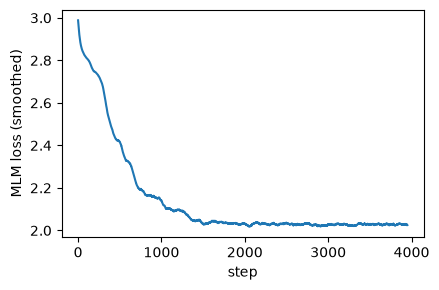

In [4]:
MASK_P = 0.15
BATCH = 256
STEPS = 4000
LR = 2e-3

Xtr = torch.from_numpy(X_train).long().to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=STEPS, pct_start=0.1)

losses = []
t0 = time.time()
model.train()
for step in range(STEPS):
    idx = torch.randint(0, Xtr.size(0), (BATCH,), device=DEVICE)
    x = Xtr[idx]
    m = torch.rand(x.shape, device=DEVICE) < MASK_P
    m[:, 0] |= ~m.any(dim=1)                       # 마스크가 하나도 없는 서열 방지
    inp = x.masked_fill(m, MASK_ID)
    logits = model(inp)
    loss = F.cross_entropy(logits[m], x[m])
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
    sched.step()
    losses.append(loss.item())
    if (step + 1) % 500 == 0:
        print(f"step {step + 1:5d}  loss {np.mean(losses[-500:]):.3f}  ({time.time() - t0:.0f}s)")

plt.figure(figsize=(4.5, 3))
plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
plt.xlabel("step")
plt.ylabel("MLM loss (smoothed)")
plt.tight_layout()
plt.show()

학습 손실은 약 2.0 근처에서 평탄해진다(seed=0, 직접 확인). 0에 가까워지지 않는 이유를 생각해 보자. 비커플링 위치처럼 문맥으로 줄일 수 없는 불확실성의 하한은 무엇인가?

## 4. 평가 — 한 위치만 가렸을 때의 정확도
테스트 서열에서 위치 p 하나만 마스킹하고 정답 잔기를 맞히는 정확도를 위치별로 잰다.

비교 기준
- **위치별 최빈값 baseline**: 훈련 데이터에서 위치 p에 가장 흔한 잔기를 항상 예측한다(문맥을 보지 않음).
- **규칙 기반 기준**: 커플링 규칙을 알고 파트너로부터 규칙대로 예측했을 때의 테스트 정확도다(표본 추정치).
- **베이즈 최적 정확도(이론 상한)**: 데이터 생성 과정을 정확히 알 때 파트너가 주어진 상태에서 달성 가능한 최대 정확도다. 결합분포에서 직접 계산한다.
  규칙 기반 예측이 항상 베이즈 최적이라는 보장은 없다. 위치별 배경 빈도가 치우쳐 있으면 달라질 수 있어 따로 계산한다.

coupled positions   : model 0.907 | position-mode baseline 0.129 | rule-based 0.907 | Bayes-optimal (theory) 0.905
uncoupled positions : model 0.128 | position-mode baseline 0.128


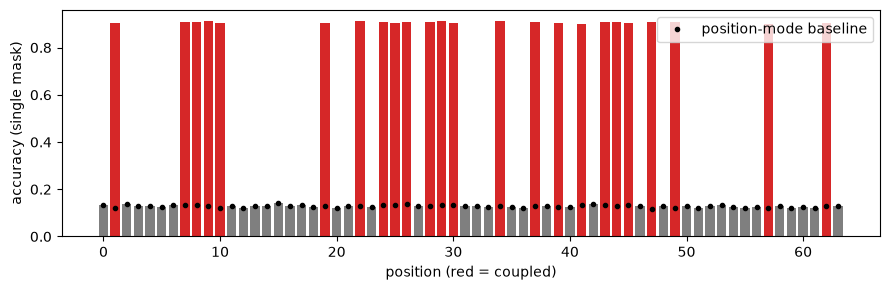

In [5]:
@torch.no_grad()
def acc_single_mask(model, X, p, bs=1000):
    model.eval()
    Xt = torch.from_numpy(X).long().to(DEVICE)
    correct = 0
    for s in range(0, Xt.size(0), bs):
        x = Xt[s:s + bs].clone()
        y = x[:, p].clone()
        x[:, p] = MASK_ID
        correct += (model(x)[:, p].argmax(-1) == y).sum().item()
    return correct / Xt.size(0)


model_acc = np.array([acc_single_mask(model, X_test, p) for p in range(L)])

mode_pred = np.array([np.bincount(X_train[:, p], minlength=V).argmax() for p in range(L)])
base_acc = np.array([(X_test[:, p] == mode_pred[p]).mean() for p in range(L)])

rule_acc, bayes_acc = {}, {}
for (i, j), pm in zip(PAIRS, PERMS):
    inv = np.argsort(pm)
    rule_acc[j] = (pm[X_test[:, i]] == X_test[:, j]).mean()      # 규칙 기반: i로부터 j 예측
    rule_acc[i] = (inv[X_test[:, j]] == X_test[:, i]).mean()     # 규칙 기반: j로부터 i 예측
    # 생성 과정으로부터 결합분포 P(x_i=a, x_j=b)를 만들어 이론적 베이즈 최적 정확도를 계산한다.
    joint = background[:, None] * NOISE * background[None, :]   # 노이즈: x_j가 배경에서 독립 추출됨
    joint[np.arange(V), pm] += background * (1 - NOISE)         # 커플링: x_j = pm[x_i]
    bayes_acc[j] = joint.max(axis=1).sum()                      # i가 주어졌을 때 j를 맞힐 최대 확률
    bayes_acc[i] = joint.max(axis=0).sum()                      # j가 주어졌을 때 i를 맞힐 최대 확률

cp = np.array(coupled_positions)
unc = np.array([p for p in range(L) if p not in set(coupled_positions)])
print(f"coupled positions   : model {model_acc[cp].mean():.3f} | position-mode baseline {base_acc[cp].mean():.3f} | "
      f"rule-based {np.mean([rule_acc[p] for p in cp]):.3f} | Bayes-optimal (theory) {np.mean([bayes_acc[p] for p in cp]):.3f}")
print(f"uncoupled positions : model {model_acc[unc].mean():.3f} | position-mode baseline {base_acc[unc].mean():.3f}")

colors = ["tab:red" if p in set(coupled_positions) else "tab:gray" for p in range(L)]
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(L), model_acc, color=colors)
ax.plot(range(L), base_acc, "k.", label="position-mode baseline")
ax.set_xlabel("position (red = coupled)")
ax.set_ylabel("accuracy (single mask)")
ax.legend()
plt.tight_layout()
plt.show()

**읽는 법**: 빨간 막대(커플링 위치)가 baseline 점(검은 점)보다 훨씬 높고 회색(비커플링)은 baseline 근처라면,
모델이 **마스킹된 위치의 파트너 잔기를 찾아 활용하는 법**을 MLM 목적함수만으로 학습한 것이다.
비커플링 위치는 문맥에서 얻을 정보가 없으므로 baseline(위치별 최빈값)이 사실상 상한이다.

참고: 모델·규칙 기반 값은 5,000개 테스트 서열에서 얻은 **표본 추정치**(표준오차 약 0.004)이고 베이즈 최적값은 이론값이다.
추정치가 이론 상한을 0.002 정도 넘는 것은 모델이 상한을 이긴 것이 아니라 표본 오차 범위 안의 차이다.

## 5. attention은 파트너를 보는가? (양방향)
커플링 위치 하나(target)를 마스킹하고, target에서 나가는 attention이 **파트너**에 얼마나 집중되는지 본다. 쌍 (i, j)에 대해 **두 방향**을 모두 잰다:
j를 마스킹했을 때 i를 보는가, i를 마스킹했을 때 j를 보는가.
(지표: 파트너에 대한 attention ÷ 나머지 위치 평균 attention, 헤드 평균·샘플 평균)

In [6]:
@torch.no_grad()
def partner_attention_ratio(model, X, target, partner, n=1000):
    model.eval()
    x = torch.from_numpy(X[:n]).long().to(DEVICE).clone()
    x[:, target] = MASK_ID
    model(x)
    ratios = []
    for b in model.blocks:
        a = b.last_attn[:, :, target, :].mean(dim=(0, 1)).cpu().numpy()   # target에서 나가는 attention (L,)
        others = np.delete(a, [partner, target])
        ratios.append(a[partner] / others.mean())
    return ratios


directed = [(j, i) for (i, j) in PAIRS] + [(i, j) for (i, j) in PAIRS]    # (target, partner): 앞 12개는 j<-i, 뒤 12개는 i<-j
ratios = np.array([partner_attention_ratio(model, X_test, t, pr) for (t, pr) in directed])
print("layer1 / layer2 의 '파트너 attention ÷ 나머지 평균'")
for k, (i, j) in enumerate(PAIRS):
    print(f"  pair ({i:2d},{j:2d})   j가 target: {ratios[k][0]:6.2f} {ratios[k][1]:6.2f}   |   i가 target: {ratios[12 + k][0]:6.2f} {ratios[12 + k][1]:6.2f}")
print("평균 (j가 target):", np.round(ratios[:12].mean(0), 2), "| 평균 (i가 target):", np.round(ratios[12:].mean(0), 2))

layer1 / layer2 의 '파트너 attention ÷ 나머지 평균'
  pair (19, 1)   j가 target:  37.69   9.86   |   i가 target:   1.75  38.66
  pair (26, 8)   j가 target:  33.31   2.20   |   i가 target:  42.76   2.97
  pair (30,39)   j가 target:  24.30   3.72   |   i가 target:  50.33   2.78
  pair (37,47)   j가 target:  36.47  17.63   |   i가 target:  34.47   1.19
  pair (44,28)   j가 target:  34.14   3.09   |   i가 target:  19.45  16.12
  pair (41,57)   j가 target:  20.91   8.62   |   i가 target:  28.22   2.14
  pair (43,49)   j가 target:  20.18   5.92   |   i가 target:  21.34   5.86
  pair (22,34)   j가 target:   6.40  46.42   |   i가 target:   1.43  30.93
  pair (29, 9)   j가 target:  15.17  43.73   |   i가 target:  28.81   0.92
  pair ( 7,24)   j가 target:   1.43  35.92   |   i가 target:  17.35  26.51
  pair (62,10)   j가 target:  42.44  15.68   |   i가 target:  23.85   2.96
  pair (25,45)   j가 target:  22.17   1.13   |   i가 target:  21.54   1.75
평균 (j가 target): [24.55 16.16] | 평균 (i가 target): [24.28 11.07]


**해석 가이드**: 비율이 1보다 크면 파트너에 평균 이상으로 attention이 모인다는 뜻이다. 층이나 헤드마다 역할이 다를 수 있고(헤드 평균은 희석 효과가 있음),
**attention은 곧 설명(explanation)이 아니다.** 파트너에 attention이 모였다는 것은 "파트너를 쓴다"는 증거와 **일치**할 뿐이다. 다음 절에서 인과적으로 확인한다.

## 6. 파트너를 바꾸면 예측이 무너지는가? (교란 실험)
target을 마스킹한 상태에서 파트너 잔기를 (a) 그대로 두기, (b) 배경 분포에서 무작위로 교체, (c) 파트너도 마스킹으로 바꾸고 정확도를 비교한다.
모델이 파트너에 의존한다면 (b), (c)에서 정확도가 baseline 쪽으로 떨어져야 한다.

In [7]:
@torch.no_grad()
def acc_with_partner(model, X, target, partner, mode, bs=1000, seed=0):
    model.eval()
    g = np.random.RandomState(seed)
    Xt = torch.from_numpy(X).long().to(DEVICE)
    correct = 0
    for st in range(0, Xt.size(0), bs):
        x = Xt[st:st + bs].clone()
        y = x[:, target].clone()
        x[:, target] = MASK_ID
        if mode == "shuffle":
            x[:, partner] = torch.from_numpy(g.choice(V, size=x.size(0), p=background)).long().to(DEVICE)
        elif mode == "mask":
            x[:, partner] = MASK_ID
        correct += (model(x)[:, target].argmax(-1) == y).sum().item()
    return correct / Xt.size(0)


targets = np.array([t for t, _ in directed])
for mode, name in [("none", "(a) 파트너 그대로"), ("shuffle", "(b) 파트너 무작위 교체"), ("mask", "(c) 파트너도 마스킹")]:
    accs = np.array([acc_with_partner(model, X_test, t, pr, mode) for t, pr in directed])
    print(f"{name:22s} 평균 정확도 {accs.mean():.3f}   (같은 target들의 위치별 최빈값 baseline {base_acc[targets].mean():.3f})")

(a) 파트너 그대로            평균 정확도 0.907   (같은 target들의 위치별 최빈값 baseline 0.129)


(b) 파트너 무작위 교체         평균 정확도 0.063   (같은 target들의 위치별 최빈값 baseline 0.129)


(c) 파트너도 마스킹           평균 정확도 0.127   (같은 target들의 위치별 최빈값 baseline 0.129)


**관찰 (seed=0, 직접 확인할 것)**
- (b) 파트너를 무작위로 바꾸면 정확도가 baseline보다도 **낮아진다**(약 0.06 < 0.13). 모델이 바뀐 파트너를 믿고 치환표대로 예측하기 때문이다. 파트너 잔기를 직접 바꾼 개입 실험의 결과이므로 attention 비율보다 강한 의존성 증거다.
- (c) 파트너를 마스킹하면 정확도가 baseline 수준(약 0.13)으로 떨어진다. 파트너가 없으면 문맥에서 얻을 정보가 없다.
- attention 비율은 모든 방향·쌍에서 적어도 한 층이 약 19배 이상이었지만, 어느 층이 그 역할을 하는지는 쌍마다 다르다.

## 7. 정리, 한계, 과제
- MLM 목적함수만으로 위치 간 의존성이 학습된다. 이것이 PLM의 임베딩에 구조·기능 정보가 담기는 직관적 근거다.
- 과제([../exercises.md](../exercises.md) 과제 2): `N_PAIRS`, `NOISE`, 훈련 샘플 수, 모델 크기를 바꿔 결과가 어떻게 달라지는지 시드 3회 이상으로 보고한다.
- **합성에서 실제로 옮길 때 주의한다.** 이 설정은 의도적으로 쉽다. (1) 커플링 쌍이 서로 겹치지 않는 **1대1** 관계이고, (2) 서열 간 **계통(phylogeny)** 구조가 없는 독립 표본이며, (3) 의존성이 항상 같은 두 위치 사이에만 존재한다.
  실제 단백질에서는 한 잔기가 여러 잔기와 접촉하는 **다대다** 관계이고, 계통 공유로 인한 **간접 상관**(직접 접촉이 없어도 생기는 상관)이 섞이며, 위치마다 보존 정도가 다르다.
  따라서 "작은 모델이 3만 개 샘플로 이론 상한에 도달했다"는 결과나 수십 배(이 실행에서 층별 평균 약 16~24배)의 attention 비율이 실제 PLM에서도 그대로 나오리라고 기대하면 안 된다.
  실제 PLM에서 attention으로부터 contact를 읽는 데는 보정과 지도 학습된 probe가 쓰인다는 점은 Rao et al. 2021 본문에서 확인한다†.
- 합성 데이터에서 잘 배운다고 해서 실제 단백질 서열의 분포(복잡한 고차 의존성)에서도 같은 학습 효율을 보장하지는 않는다.